##### imports

In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import shutil
import random

from scipy.stats import loguniform, uniform

from sklearn.model_selection import train_test_split,KFold,cross_val_score,RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline,Pipeline
from sklearn.metrics import (accuracy_score, precision_score,
                             f1_score,recall_score, roc_auc_score,
                             ConfusionMatrixDisplay, confusion_matrix,
                             classification_report)

### Data Loading

In [6]:
og_df = pd.read_csv("../../data/oc_risk50k_single_dataset.csv")
df = og_df.copy()

print(df.shape,"\n\n")
df.head(5)

(50000, 52) 




,Patient_ID,Age,Menopausal_Status,Age_At_Menarche,Age_At_Menopause,Family_History,BRCA1_Status,BRCA2_Status,Lynch_Syndrome_Status,BMI,...,Charlson_Comorbidity_Index,ECOG_Performance_Status,Creatinine,Liver_Enzyme_Level,Treatment_Status,Time_To_Progression,Follow_Up_Status,Partition,Ovarian_Cancer_Status,Risk_Category
0,PAT_00001,53.8,1,11.0,48.6,0,0,0,0,34.5,...,1,2,0.98,30.6,0,-1.0,2,Train,0,0
1,PAT_00002,66.8,1,13.2,50.4,1,0,0,0,18.5,...,1,1,1.01,33.7,3,25.1,0,Train,1,1
2,PAT_00003,51.9,1,13.2,50.9,1,0,0,0,23.2,...,0,2,0.73,17.8,2,5.5,0,Train,1,2
3,PAT_00004,67.6,1,12.3,51.1,0,0,0,0,24.7,...,2,1,1.01,25.3,2,70.0,0,Test,1,2
4,PAT_00005,80.5,1,14.9,52.1,1,0,0,0,22.0,...,0,0,0.85,30.1,0,-1.0,1,Test,0,0


In [9]:
non_invasive_cols = ['Age',
                     'Menopausal_Status',
                     'Age_At_Menarche',
                     'BMI',
                     'Parity',
                     'Oral_Contraceptive_History',
                     'Endometriosis_History',
                     'Hormone_Therapy_History',
                     'Tubal_Ligation_History',
                     'Family_History',
                     'Abdominal_Bloating',
                     'Pelvic_Pain',
                     'Early_Satiety',
                     'Urinary_Urgency',
                     'Unexplained_Weight_Loss']

In [16]:
target = "Ovarian_Cancer_Status"

#### Original Model Report:

In [136]:
# can probably remove:
remove_cols = ["BMI","Age","Parity","Age_At_Menarche","Hormone_Therapy_History"]

In [18]:
metrics_df = pd.DataFrame(index=["Train_Acc","Test_Acc","Precision","Recall","F1_Score","ROC_AUC"])

              precision    recall  f1-score   support

           0       0.89      0.91      0.90      4992
           1       0.91      0.88      0.90      5008

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



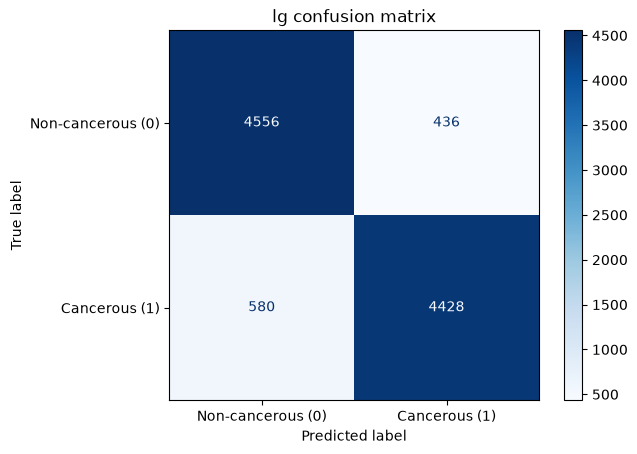



              precision    recall  f1-score   support

           0       0.87      0.92      0.89      4992
           1       0.91      0.86      0.89      5008

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



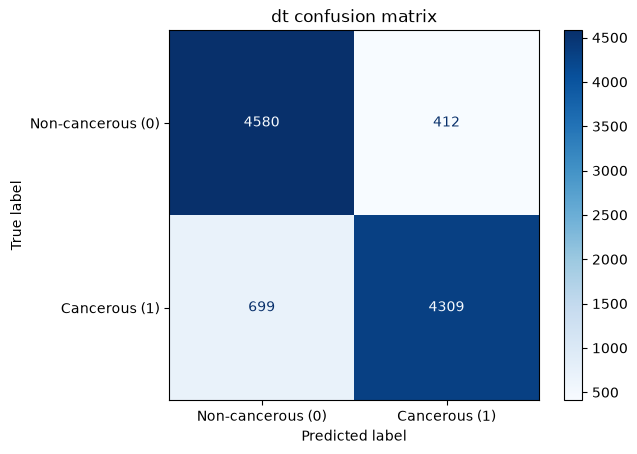

,non_inv_lg,non_inv_dt
Train_Acc,0.8992,0.8946
Test_Acc,0.8984,0.8889
Precision,0.9104,0.9127
Recall,0.8842,0.8604
F1_Score,0.8971,0.8858
ROC_AUC,0.9617,0.9504


In [71]:
name = "non_inv"

x = df[non_invasive_cols]
y = df[target]

x_train,x_test,y_train,y_test = train_test_split(x,y,train_size=0.8,random_state=1119)

models = {
    "lg": make_pipeline(SimpleImputer(strategy='mean'), StandardScaler(), LogisticRegression(max_iter=1000)),
    "dt": make_pipeline(SimpleImputer(strategy='mean'), DecisionTreeClassifier(max_depth=7,random_state=1119))
}

for abbr, pipeline in models.items():
    pipeline.fit(x_train, y_train)
    y_pred = pipeline.predict(x_test)

    metrics_df[f"{name}_{abbr}"] = [
        round(accuracy_score(y_train, pipeline.predict(x_train)), 4),
        round(accuracy_score(y_test,y_pred),4),
        round(precision_score(y_test,y_pred),4),
        round(recall_score(y_test,y_pred),4),
        round(f1_score(y_test,y_pred),4),
        round(roc_auc_score(np.array(y_test).reshape(-1),
                            pipeline.predict_proba(x_test)[:, 1]),4)
    ]

# feature importances
# model = models["lg"].named_steps['logisticregression']
# lg_importances[name] = pd.Series(model.coef_[0], index=x_train.columns).abs().sort_values(ascending=False)

# model = models["dt"].named_steps['decisiontreeclassifier']
# dt_importances[name] = pd.Series(model.feature_importances_, index=x_train.columns).sort_values(ascending=False)

# print(f"===== {name.upper()} =====")
# print("\nLogReg |coef| (standardized):")
# print(lg_importances[name])
# print("\nDecision Tree importances:")
# print(dt_importances[name],"\n\n")

    print(classification_report(y_test, y_pred))
# confusion matrix

    cm = confusion_matrix(y_test, y_pred)
    #print(cm)
    
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=["Non-cancerous (0)", "Cancerous (1)"]
    )
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f"{abbr} confusion matrix")
    plt.show()
    print("\n")


metrics_df

**LogReg has fewer false negatives

## Deep Dive

##### Cross Val (no hyperparameter tuning)

In [158]:
kf = KFold(n_splits=5, shuffle=True, random_state=1119)

model = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(random_state=1119, max_iter=1000))
    ])

cv_acc = cross_val_score(model, x, y, cv=kf, scoring="accuracy")
cv_rec = cross_val_score(model, x, y, cv=kf, scoring="recall")
cv_roc = cross_val_score(model, x, y, cv=kf, scoring="roc_auc")

pd.DataFrame(data = np.array([cv_acc,cv_rec,cv_roc]).T,columns=["accuracy","recall","roc_auc"]).mean()

accuracy    0.898700
recall      0.886089
roc_auc     0.962781
dtype: float64

#### Hyperparameter tuning

In [128]:
# prepare model + data 

x_train,x_test,y_train,y_test = train_test_split(x,y,train_size=0.8,random_state=1119)

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(
        solver="saga", # supports multiple penalties
        max_iter=1000,
        random_state=1119
    ))
])

In [134]:
param_distributions = [
    {
        "logreg__C": loguniform(1e-4, 1e2),
        "logreg__l1_ratio": uniform(0, 1),  
    },
]

search = RandomizedSearchCV(
    estimator=pipe,
    param_distributions=param_distributions,
    n_iter=30,
    cv=5,
    scoring=["accuracy","recall","roc_auc"], 
    refit="recall",
    n_jobs=-1,
    random_state=1119,
)

search.fit(x_train,y_train)

print("Best CV Score:", round(search.best_score_, 4))
print("Best Params:", search.best_params_)
print("Test Set Score:", round(search.score(x_test, y_test), 4))

Best CV Score: 0.8863
Best Params: {'logreg__C': np.float64(0.10221588934772381), 'logreg__l1_ratio': np.float64(0.1975103156436263)}
Test Set Score: 0.8842


^^ tuning doesn't obviously improve model metrics

## Reduced Non-Invasive Model

In [140]:
remove_cols

['BMI', 'Age', 'Parity', 'Age_At_Menarche', 'Hormone_Therapy_History']

In [144]:
print(x.shape)
x.head()

(50000, 15)


,Age,Menopausal_Status,Age_At_Menarche,BMI,Parity,Oral_Contraceptive_History,Endometriosis_History,Hormone_Therapy_History,Tubal_Ligation_History,Family_History,Abdominal_Bloating,Pelvic_Pain,Early_Satiety,Urinary_Urgency,Unexplained_Weight_Loss
0,53.8,1,11.0,34.5,3,1,0,0,0,0,1,0,0,0,0
1,66.8,1,13.2,18.5,2,0,0,0,0,1,0,1,1,1,1
2,51.9,1,13.2,23.2,3,0,0,0,0,1,1,1,0,0,0
3,67.6,1,12.3,24.7,0,0,0,0,0,0,1,0,0,0,0
4,80.5,1,14.9,22.0,3,1,0,0,1,1,0,0,0,0,0


In [146]:
z = x.drop(labels=remove_cols,axis=1)
print(z.shape)
z.head(5)

(50000, 10)


,Menopausal_Status,Oral_Contraceptive_History,Endometriosis_History,Tubal_Ligation_History,Family_History,Abdominal_Bloating,Pelvic_Pain,Early_Satiety,Urinary_Urgency,Unexplained_Weight_Loss
0,1,1,0,0,0,1,0,0,0,0
1,1,0,0,0,1,0,1,1,1,1
2,1,0,0,0,1,1,1,0,0,0
3,1,0,0,0,0,1,0,0,0,0
4,1,1,0,1,1,0,0,0,0,0


              precision    recall  f1-score   support

           0       0.88      0.92      0.90      4992
           1       0.91      0.88      0.90      5008

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



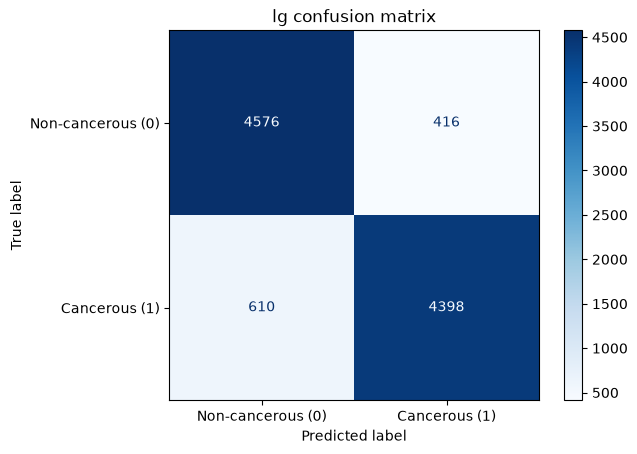



              precision    recall  f1-score   support

           0       0.87      0.92      0.89      4992
           1       0.91      0.86      0.89      5008

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



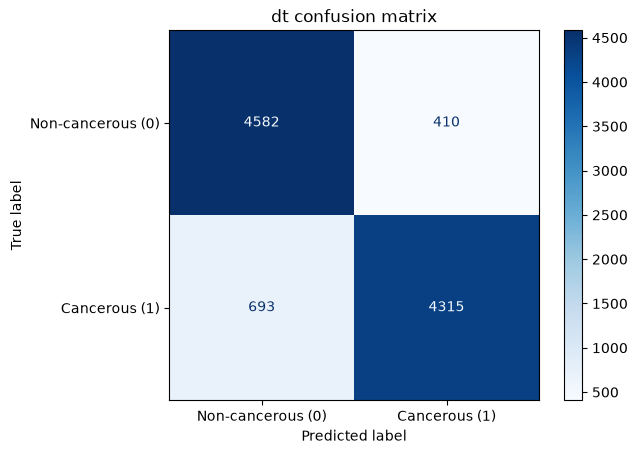

,non_inv_lg,non_inv_dt,non_inv_reduced_lg,non_inv_reduced_dt
Train_Acc,0.8992,0.8946,0.8981,0.8926
Test_Acc,0.8984,0.8889,0.8974,0.8897
Precision,0.9104,0.9127,0.9136,0.9132
Recall,0.8842,0.8604,0.8782,0.8616
F1_Score,0.8971,0.8858,0.8955,0.8867
ROC_AUC,0.9617,0.9504,0.9609,0.9528


In [150]:
name = "non_inv_reduced"

z_train,z_test,y_train,y_test = train_test_split(z,y,train_size=0.8,random_state=1119)

models = {
    "lg": make_pipeline(SimpleImputer(strategy='mean'), StandardScaler(), LogisticRegression(max_iter=1000)),
    "dt": make_pipeline(SimpleImputer(strategy='mean'), DecisionTreeClassifier(max_depth=7,random_state=1119))
}

for abbr, pipeline in models.items():
    pipeline.fit(z_train, y_train)
    y_pred = pipeline.predict(z_test)

    metrics_df[f"{name}_{abbr}"] = [
        round(accuracy_score(y_train, pipeline.predict(z_train)), 4),
        round(accuracy_score(y_test,y_pred),4),
        round(precision_score(y_test,y_pred),4),
        round(recall_score(y_test,y_pred),4),
        round(f1_score(y_test,y_pred),4),
        round(roc_auc_score(np.array(y_test).reshape(-1),
                            pipeline.predict_proba(z_test)[:, 1]),4)
    ]

    print(classification_report(y_test, y_pred))
    
# confusion matrix

    cm = confusion_matrix(y_test, y_pred)
    #print(cm)
    
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=["Non-cancerous (0)", "Cancerous (1)"]
    )
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f"{abbr} confusion matrix")
    plt.show()
    print("\n")


metrics_df

In [154]:
kf = KFold(n_splits=5, shuffle=True, random_state=1119)

model = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(random_state=1119, max_iter=1000))
    ])

lg_cv_acc = cross_val_score(model, z, y, cv=kf, scoring="accuracy")
lg_cv_rec = cross_val_score(model, z, y, cv=kf, scoring="recall")
lg_cv_roc = cross_val_score(model, z, y, cv=kf, scoring="roc_auc")

pd.DataFrame(data = np.array([lg_cv_acc,lg_cv_rec,lg_cv_roc]).T,columns=["accuracy","recall","roc_auc"]).mean()

accuracy    0.89758
recall      0.88025
roc_auc     0.96173
dtype: float64

*Performance maintained through feature reduction*

In [162]:
df.groupby("Abdominal_Bloating")["Ovarian_Cancer_Status"].mean()

Abdominal_Bloating
0    0.245498
1    0.838522
Name: Ovarian_Cancer_Status, dtype: float64

^^Unrealistic proportion

In [164]:
z.columns

Index(['Menopausal_Status', 'Oral_Contraceptive_History',
       'Endometriosis_History', 'Tubal_Ligation_History', 'Family_History',
       'Abdominal_Bloating', 'Pelvic_Pain', 'Early_Satiety', 'Urinary_Urgency',
       'Unexplained_Weight_Loss'],
      dtype='str')

In [171]:
param_distributions = [
    {
        "logreg__C": loguniform(1e-4, 1e2),
        "logreg__l1_ratio": uniform(0, 1),  
    },
]

search = RandomizedSearchCV(
    estimator=pipe,
    param_distributions=param_distributions,
    n_iter=30,
    cv=5,
    scoring=["accuracy","recall","roc_auc"], 
    refit="roc_auc",
    n_jobs=-1,
    random_state=1119,
)

search.fit(z_train,y_train)

print("Best CV Score:", round(search.best_score_, 4))
print("Best Params:", search.best_params_)
print("Test Set ROC:", round(search.score(z_test, y_test), 4))

Best CV Score: 0.9619
Best Params: {'logreg__C': np.float64(0.10221588934772381), 'logreg__l1_ratio': np.float64(0.1975103156436263)}
Test Set ROC: 0.961


*model is already reduced, overfitting has not been observed, so tuning for regularization is largely unnecessary*

In [176]:
df[z.columns].isnull().sum()

Menopausal_Status             0
Oral_Contraceptive_History    0
Endometriosis_History         0
Tubal_Ligation_History        0
Family_History                0
Abdominal_Bloating            0
Pelvic_Pain                   0
Early_Satiety                 0
Urinary_Urgency               0
Unexplained_Weight_Loss       0
dtype: int64

In [196]:
df[list(z.columns) + [target]].to_csv("../data/non_invasive_df.csv",index=False)

In [210]:
!head -n 5 ../data/non_invasive_df.csv

Menopausal_Status,Oral_Contraceptive_History,Endometriosis_History,Tubal_Ligation_History,Family_History,Abdominal_Bloating,Pelvic_Pain,Early_Satiety,Urinary_Urgency,Unexplained_Weight_Loss,Ovarian_Cancer_Status
1,1,0,0,0,1,0,0,0,0,0
1,0,0,0,1,0,1,1,1,1,1
1,0,0,0,1,1,1,0,0,0,1
1,0,0,0,0,1,0,0,0,0,1


python(69297) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
